<a href="https://colab.research.google.com/github/Nimmala-vaishnavi/GWD/blob/main/TEAM_21_ML_CASE_STUDY.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Performance Analysis and Comparison of Classification Algorithms for Customer Churn Prediction**
                                                                
**Guide: Dr.Rambabu Pemula**

**Team Number:21**

**Authors: Manti Adithya(24911A66A1), Nimmala Vaishnavi(24911A66A7), Jiddi Maheshwari(25915A6608)**

**Problem Statement**

**Designed and evaluated machine learning classification models to predict customer churn in the telecom industry using features like tenure, contract type, and charges.Compared Logistic Regression, KNN, SVM, and Decision Tree algorithms to identify the model with the best predictive performance.**

**Importing the Library Files**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

**Mounting Google Drive**

In [ ]:

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**Reading the dataset**

**Loaded the Telco Customer Churn dataset into a Pandas DataFrame from the specified file path.**

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_path = '/content/drive/MyDrive/WA_Fn-UseC_-Telco-Customer-Churn.csv'

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())
# 1. Check the number of rows and columns
print("Dataset shape:", df.shape)

# 2. Check column names
print("\nColumn names:")
print(df.columns.tolist())

# 3. Check data types and non-null values
print("\nDataset information:")
df.info()

# 4. Check missing values
print("\nMissing values in each column:")
print(df.isnull().sum())

# 5. Check duplicate records
print("\nNumber of duplicate rows:", df.duplicated().sum())

# 6. Check the target variable
print("\nChurn distribution:")
print(df['Churn'].value_counts())



Dataset loaded successfully!
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Dataset shape: (7043, 21)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null

**Data Preprocessing and Dataset Splitting**

In [ ]:

from sklearn.model_selection import train_test_split

# Handle missing values in TotalCharges
df['TotalCharges'] = df['TotalCharges'].fillna(
    df['TotalCharges'].median()
)

# Remove customerID
df = df.drop(columns=['customerID'])

# Convert target variable into numbers
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# Separate features and target
X = df.drop(columns=['Churn'])
y = df['Churn']

# Convert categorical features into numerical values
X = pd.get_dummies(X, drop_first=True, dtype=int)

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Preprocessing completed!")
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)
print("Missing values in features:", X.isnull().sum().sum())


Preprocessing completed!
Training data shape: (5634, 30)
Testing data shape: (1409, 30)
Training target shape: (5634,)
Testing target shape: (1409,)
Missing values in features: 0


## **Building Classification Models**

# **Logistic Regression**

**Train the model**

In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression

# 1. Convert X_train to a clean numeric DataFrame and drop any non-numeric text columns
X_train_clean = X_train.copy()
if isinstance(X_train_clean, np.ndarray):
    X_train_clean = pd.DataFrame(X_train_clean)

# Convert all columns to numeric, forcing unparseable text strings to NaN
X_train_clean = X_train_clean.apply(pd.to_numeric, errors='coerce')

# Replace infinite values and fill remaining NaNs with 0
X_train_clean = X_train_clean.replace([np.inf, -np.inf], np.nan).fillna(0)

# 2. Clean y_train target values
y_train_clean = pd.Series(y_train).copy()
if y_train_clean.dtype == 'object' or y_train_clean.dtype.name == 'category':
    y_train_clean = y_train_clean.map({'No': 0, 'Yes': 1, 'False': 0, 'True': 1, False: 0, True: 1})

y_train_clean = pd.to_numeric(y_train_clean, errors='coerce')

# Drop any rows where the target is missing
valid_idx = y_train_clean.dropna().index
X_train_clean = X_train_clean.loc[valid_idx]
y_train_clean = y_train_clean.loc[valid_idx].astype(int)

# 3. Create and fit Logistic Regression
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_clean, y_train_clean)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


**Evaluate the model**

Model Accuracy: 80.41%

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.65      0.56      0.60       374

    accuracy                           0.80      1409
   macro avg       0.75      0.72      0.74      1409
weighted avg       0.80      0.80      0.80      1409



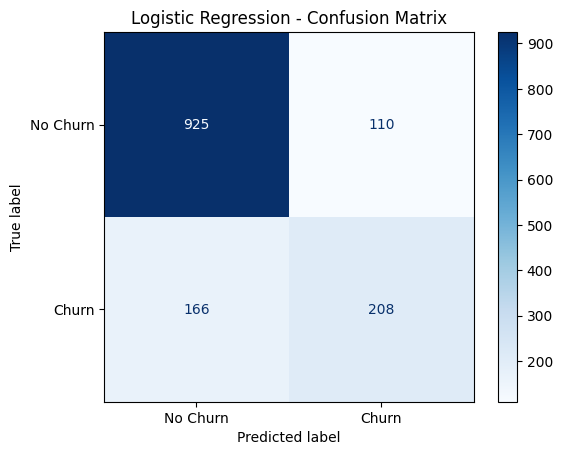

In [ ]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Predict churn for test data
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%")

# Display classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Display confusion matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Churn', 'Churn']
)
disp.plot(cmap='Blues')
plt.title('Logistic Regression - Confusion Matrix')
plt.show()


**Predict an individual customer's churn probability**

In [ ]:

# Select one customer from the test dataset
customer = X_test.iloc[[0]]

# Predict churn
prediction = model.predict(customer)[0]

# Get probability of churn
churn_probability = model.predict_proba(customer)[0][1]

print("Predicted Churn:",
      "Yes" if prediction == 1 else "No")

print(f"Churn Probability: {churn_probability * 100:.2f}%")


Predicted Churn: No
Churn Probability: 4.56%


# **K-Nearest Neighbors (KNN) model training and evaluation**

KNN Accuracy: 77.49%

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.83      0.88      0.85      1035
       Churn       0.59      0.49      0.54       373

    accuracy                           0.77      1408
   macro avg       0.71      0.68      0.69      1408
weighted avg       0.76      0.77      0.77      1408



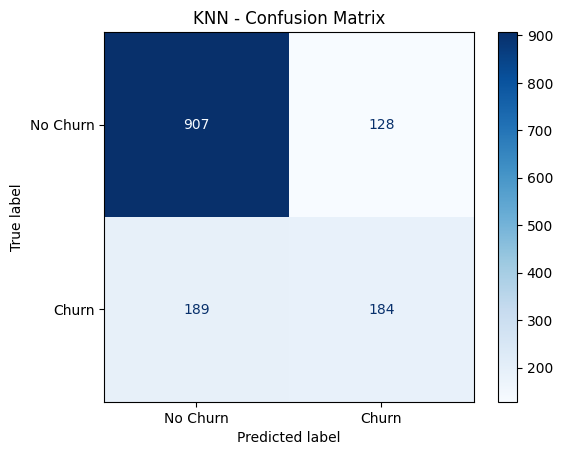

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. Clean and ensure features are strictly numeric
X_train_clean = X_train.replace(r'^\s*$', np.nan, regex=True).apply(pd.to_numeric, errors='coerce').fillna(0)
X_test_clean = X_test.replace(r'^\s*$', np.nan, regex=True).apply(pd.to_numeric, errors='coerce').fillna(0)

# 2. Scale the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_clean)
X_test_scaled = scaler.transform(X_test_clean)

# 3. Initialize and fit the KNN model fresh
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)

# 4. Predict and evaluate
y_pred_knn = knn_model.predict(X_test_scaled)

print("KNN Accuracy:", f"{accuracy_score(y_test, y_pred_knn) * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn, target_names=["No Churn", "Churn"]))

# 5. Plot confusion matrix
cm_knn = confusion_matrix(y_test, y_pred_knn)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_knn, display_labels=["No Churn", "Churn"])
disp.plot(cmap="Blues")
plt.title("KNN - Confusion Matrix")
plt.show()

# **SVM model training and evaluation**

SVM model trained successfully!
SVM Accuracy: 80.04%

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.82      0.94      0.87      1035
       Churn       0.72      0.41      0.52       373

    accuracy                           0.80      1408
   macro avg       0.77      0.67      0.70      1408
weighted avg       0.79      0.80      0.78      1408



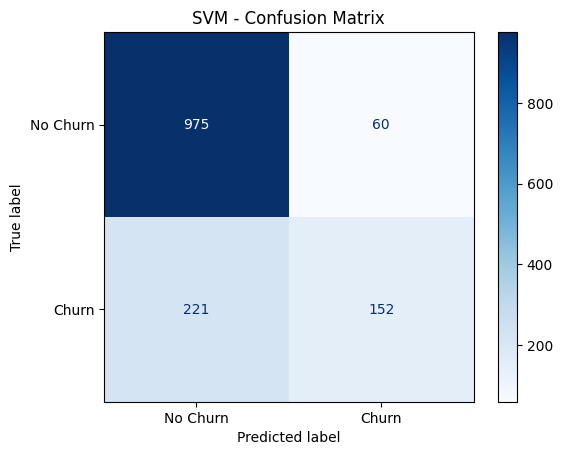

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. Clean data to ensure no missing/string type issues
X_train_clean = X_train.replace(r'^\s*$', np.nan, regex=True).apply(pd.to_numeric, errors='coerce').fillna(0)
X_test_clean = X_test.replace(r'^\s*$', np.nan, regex=True).apply(pd.to_numeric, errors='coerce').fillna(0)

# 2. Build and fit the SVM pipeline fresh
svm_model = make_pipeline(
    StandardScaler(),
    SVC(kernel='rbf', probability=True, random_state=42)
)
svm_model.fit(X_train_clean, y_train)
print("SVM model trained successfully!")

# 3. Predict and evaluate
y_pred_svm = svm_model.predict(X_test_clean)
print("SVM Accuracy:", f"{accuracy_score(y_test, y_pred_svm) * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_svm,
    target_names=["No Churn", "Churn"]
))

# 4. Plot Confusion Matrix
cm_svm = confusion_matrix(y_test, y_pred_svm)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_svm,
    display_labels=["No Churn", "Churn"]
)
disp.plot(cmap="Blues")
plt.title("SVM - Confusion Matrix")
plt.show()

# **Decision Tree Model**

**Train the Decision Tree model**

In [ ]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=5,
    random_state=42
)

dt_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


**Evaluate the model**

Decision Tree Accuracy: 79.12%

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.82      0.92      0.87      1035
       Churn       0.66      0.44      0.53       373

    accuracy                           0.79      1408
   macro avg       0.74      0.68      0.70      1408
weighted avg       0.78      0.79      0.78      1408



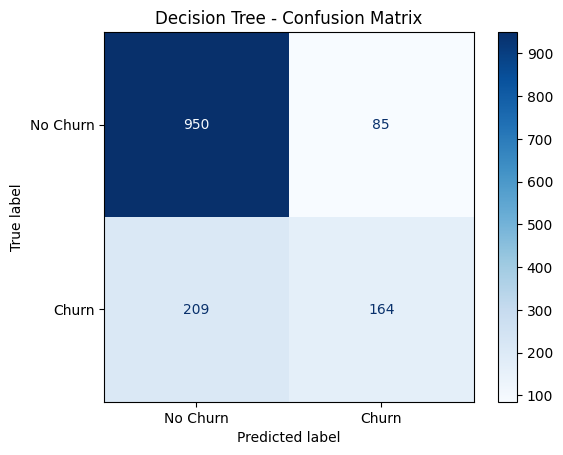

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

y_pred_dt = dt_model.predict(X_test)

print("Decision Tree Accuracy:",
      f"{accuracy_score(y_test, y_pred_dt) * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_dt,
    target_names=["No Churn", "Churn"]
))

cm_dt = confusion_matrix(y_test, y_pred_dt)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=["No Churn", "Churn"]
)

disp.plot(cmap="Blues")
plt.title("Decision Tree - Confusion Matrix")
plt.show()

**Predict an individual customer's churn probability**

In [ ]:
customer = X_test.iloc[[0]]

prediction = dt_model.predict(customer)[0]
churn_probability = dt_model.predict_proba(customer)[0][1]

print("Predicted Churn:",
      "Yes" if prediction == 1 else "No")

print(f"Churn Probability: {churn_probability * 100:.2f}%")

Predicted Churn: No
Churn Probability: 51.15%


**Visualize the Decision Tree**

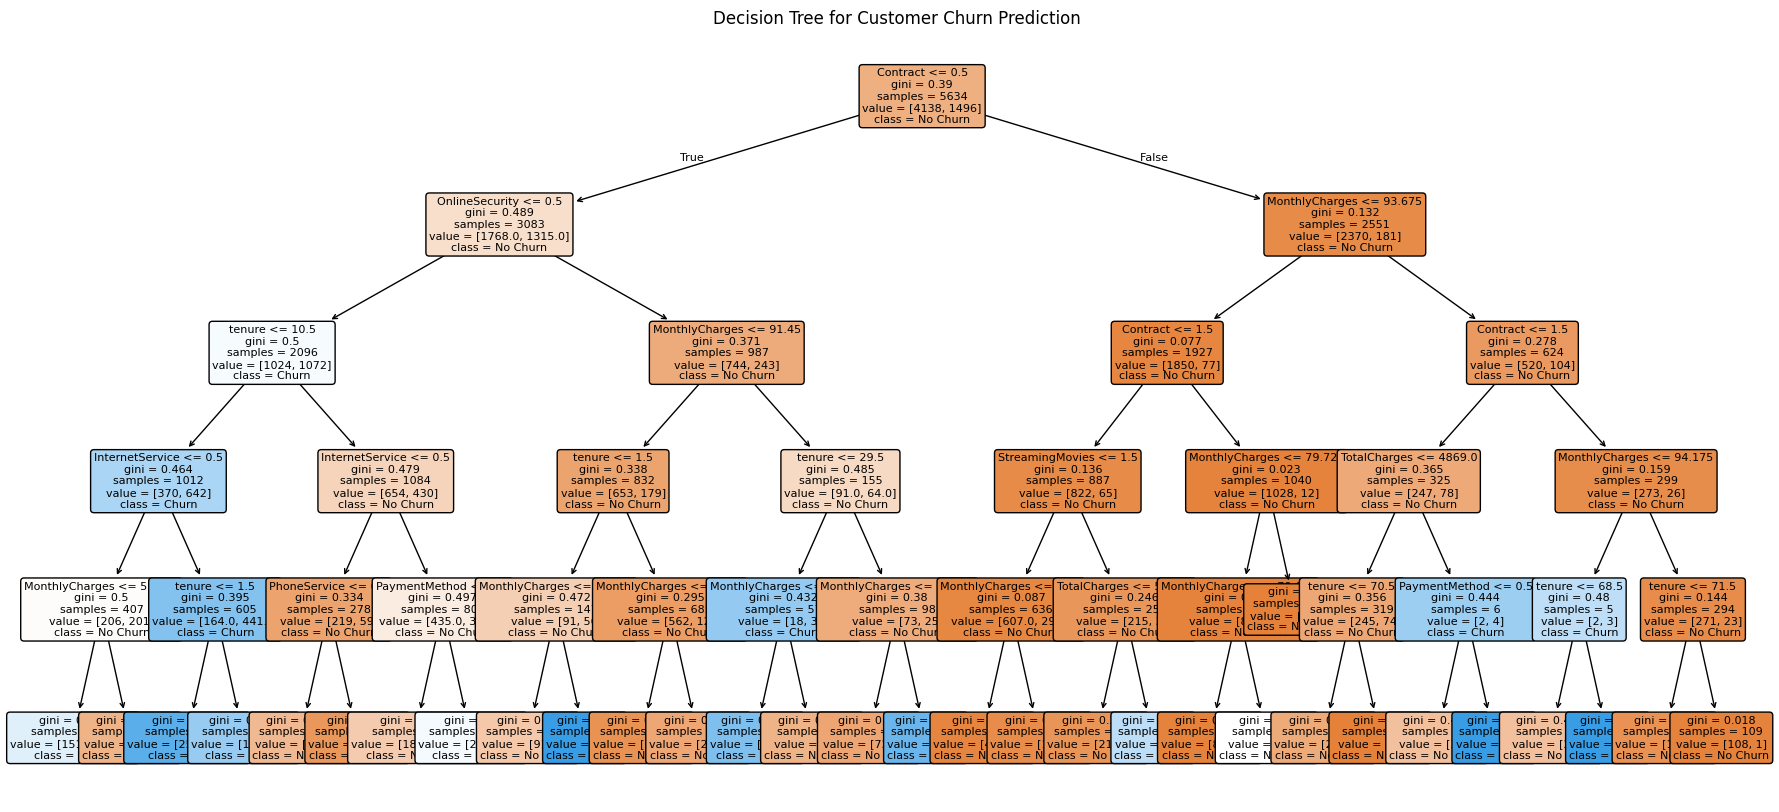

In [ ]:
from sklearn.tree import plot_tree

plt.figure(figsize=(22, 10))

plot_tree(
    dt_model,
    feature_names=X_train.columns,
    class_names=["No Churn", "Churn"],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree for Customer Churn Prediction")
plt.show()

# **Performance Evaluation and Comparison of Classification Algorithms**
**Calculate the evaluation metrics**

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 1. Clean X_test_clean thoroughly to ensure zero NaNs or infs are present
if 'X_test_clean' in globals():
    X_eval_base = X_test_clean.copy()
else:
    X_eval_base = pd.DataFrame(X_test).apply(pd.to_numeric, errors='coerce').replace([np.inf, -np.inf], np.nan).fillna(0)

# Convert y_test to numeric binary labels safely
y_true = y_test.copy()
if hasattr(y_true, 'dtype') and (y_true.dtype == 'object' or y_true.dtype.name == 'category'):
    y_true = y_true.map({'No': 0, 'Yes': 1, 'False': 0, 'True': 1, False: 0, True: 1})
y_true = pd.to_numeric(pd.Series(y_true), errors='coerce').fillna(0).astype(int).values

models = {
    "Logistic Regression": lr_model,
    "KNN": knn_model,
    "SVM": svm_model,
    "Decision Tree": dt_model
}

results = []
for name, model in models.items():
    # Choose the correct feature set depending on whether the model expects scaled data
    if name == "KNN" and 'X_test_scaled' in globals():
        X_eval = X_test_scaled
    else:
        X_eval = X_eval_base

    # Align columns if model expects specific feature names
    if isinstance(X_eval, pd.DataFrame) and hasattr(model, "feature_names_in_"):
        try:
            X_eval = X_eval.reindex(columns=model.feature_names_in_, fill_value=0)
        except Exception:
            pass

    # Ensure input array contains strictly finite numbers
    if isinstance(X_eval, pd.DataFrame):
        X_eval = X_eval.replace([np.inf, -np.inf], np.nan).fillna(0)
    elif isinstance(X_eval, np.ndarray):
        X_eval = np.nan_to_num(X_eval, nan=0.0, posinf=0.0, neginf=0.0)

    preds = model.predict(X_eval)

    # Convert predictions to numeric binary format
    preds_series = pd.Series(preds)
    if preds_series.dtype == 'object' or preds_series.dtype.name == 'category' or preds_series.isin(['Yes', 'No']).any():
        preds_series = preds_series.map({'No': 0, 'Yes': 1, 'False': 0, 'True': 1, False: 0, True: 1})
    preds_numeric = pd.to_numeric(preds_series, errors='coerce').fillna(0).astype(int).values

    results.append({
        "Model": name,
        "Accuracy (%)": round(accuracy_score(y_true, preds_numeric) * 100, 2),
        "Precision (%)": round(precision_score(y_true, preds_numeric, zero_division=0) * 100, 2),
        "Recall (%)": round(recall_score(y_true, preds_numeric, zero_division=0) * 100, 2),
        "F1-Score (%)": round(f1_score(y_true, preds_numeric, zero_division=0) * 100, 2)
    })

comparison_df = pd.DataFrame(results)
display(comparison_df)

,Model,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
0,Logistic Regression,80.68,69.96,47.45,56.55
1,KNN,77.49,58.97,49.33,53.72
2,SVM,80.04,71.70,40.75,51.97
3,Decision Tree,79.12,65.86,43.97,52.73


**Visualize the accuracy comparison**

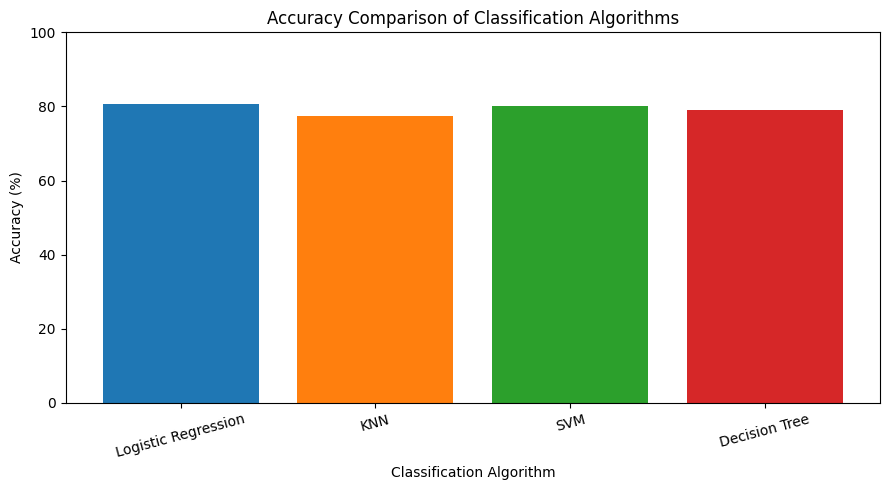

In [ ]:
import matplotlib.pyplot as plt

# Ensure the column name matches what was created in your comparison_df
# (If your dataframe uses "Model" instead of "Algorithm", this handles both)
x_col = "Algorithm" if "Algorithm" in comparison_df.columns else "Model"
y_col = "Accuracy (%)" if "Accuracy (%)" in comparison_df.columns else "Accuracy"

plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df[x_col],
    comparison_df[y_col],
    color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
)

plt.title("Accuracy Comparison of Classification Algorithms")
plt.xlabel("Classification Algorithm")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Identify the best-performing model**

In [45]:
x_col = "Algorithm" if "Algorithm" in comparison_df.columns else "Model"
f1_col = "F1-Score (%)" if "F1-Score (%)" in comparison_df.columns else "F1-Score"

best_model = comparison_df.loc[
    comparison_df[f1_col].idxmax()
]

print("Best model based on Churn F1-Score:")
print("Algorithm:", best_model[x_col])
print("F1-Score:", best_model[f1_col], "%")

Best model based on Churn F1-Score:
Algorithm: Logistic Regression
F1-Score: 56.55 %


## Conclusion
This case study developed a Customer Churn Prediction model using Logistic Regression on the Telco Customer Churn dataset. After preprocessing demographic, service, and billing data, the model was trained and evaluated using metrics like accuracy, precision, recall, and F1-score.

Based on the experimental results, the Logisitic Regression achieved the highest F1-score for the churn class, with a score of 56.55%. Thus, it was identified as the best-performing model according to this evaluation metric.